# Heart Disease Prediction — Step 2: Exploratory Data Analysis (EDA)

This notebook explores the **cleaned** dataset (894 unique patients, no missing values) to understand:
- What the features look like individually
- How each feature relates to the target (presence of heart disease)
- Whether any features are strongly correlated with each other

No modelling happens here — the goal is to understand the data before we build anything.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

df = pd.read_csv('heart_disease_cleaned.csv')
print("Shape:", df.shape)
df.head()

Shape: (894, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145.0,233.0,1.0,0.0,150.0,0.0,2.3,0.0,0.0,1.0,1
1,37,1,2,130.0,250.0,0.0,1.0,187.0,0.0,3.5,0.0,0.0,2.0,1
2,41,0,1,130.0,204.0,0.0,0.0,172.0,0.0,1.4,2.0,0.0,2.0,1
3,56,1,1,120.0,236.0,0.0,1.0,178.0,0.0,0.8,2.0,0.0,2.0,1
4,57,0,0,120.0,354.0,0.0,1.0,163.0,1.0,0.6,2.0,0.0,2.0,1


## 1. What do the columns mean?

A quick reference, since some column names are abbreviated clinical terms:

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | 1 = male, 0 = female |
| `cp` | Chest pain type (0–3) |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| `restecg` | Resting ECG results (0–2) |
| `thalachh` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = yes, 0 = no) |
| `oldpeak` | ST depression induced by exercise, relative to rest |
| `slope` | Slope of the peak exercise ST segment (0–2) |
| `ca` | Number of major vessels coloured by fluoroscopy (0–4) |
| `thal` | Thalassemia result (0–3) |
| `target` | 1 = heart disease present, 0 = not present |

`age`, `trestbps`, `chol`, `thalachh`, `oldpeak` are **continuous** (a number on a scale).
The rest are **categorical**, even though they're stored as numbers (they're codes for categories).

In [2]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalachh', 'oldpeak']
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

df[continuous_cols].describe()

,age,trestbps,chol,thalachh,oldpeak
count,894.000000,894.000000,894.000000,894.000000,894.000000
mean,52.302013,131.949664,249.043624,145.994407,0.913758
std,9.205776,17.527605,56.342809,23.700468,1.105398
min,28.000000,92.000000,85.000000,71.000000,0.000000
25%,45.000000,120.000000,212.000000,130.000000,0.000000
50%,53.000000,130.000000,242.500000,150.000000,0.500000
75%,59.000000,140.000000,277.000000,163.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


## 2. Target balance

Before anything else, it's important to check whether the two classes (disease / no disease) are
roughly balanced. A big imbalance would mean we need to be more careful later, when training and
evaluating the model.

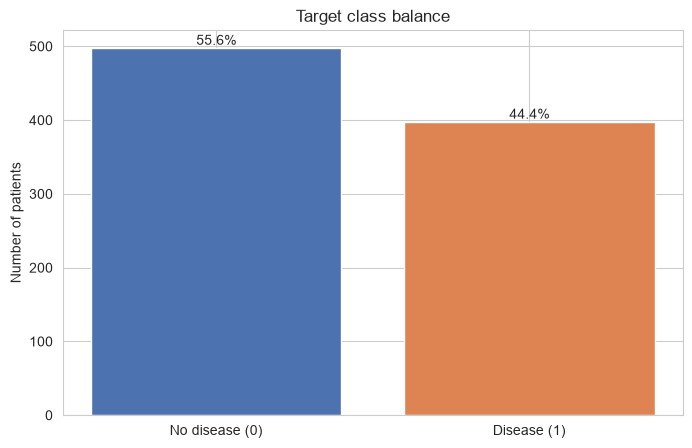

target
0    497
1    397
Name: count, dtype: int64


In [3]:
counts = df['target'].value_counts().sort_index()
pct = (counts / len(df) * 100).round(1)

fig, ax = plt.subplots()
bars = ax.bar(['No disease (0)', 'Disease (1)'], counts.values, color=['#4C72B0', '#DD8452'])
ax.set_ylabel('Number of patients')
ax.set_title('Target class balance')
for bar, p in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, f'{p}%', ha='center')
plt.show()

print(counts)

**Takeaway:** the classes are reasonably balanced (roughly 55% / 45%), so we won't need special
techniques like class re-weighting or oversampling later — accuracy alone will be a meaningful metric.

## 3. Distributions of continuous features

How each numeric feature is spread out, split by target, to see if there's an obvious difference
between patients with and without heart disease.

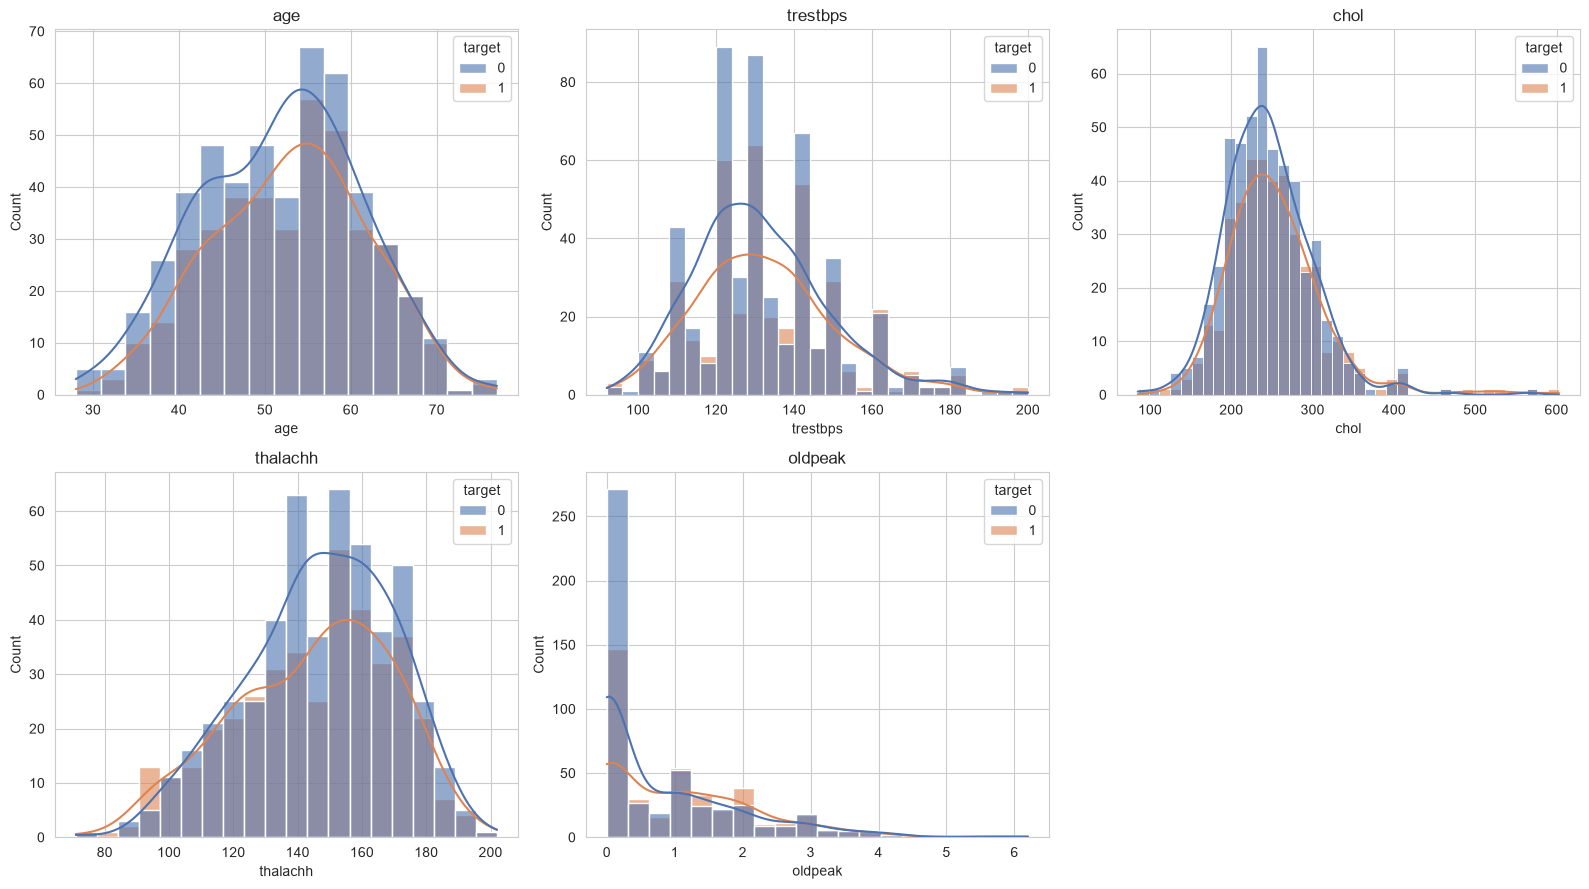

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.histplot(data=df, x=col, hue='target', kde=True, ax=axes[i], palette=['#4C72B0', '#DD8452'], alpha=0.6)
    axes[i].set_title(col)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

**What to look for:** `thalachh` (max heart rate) and `oldpeak` show the clearest separation between
the two groups — patients with heart disease tend to have a lower max heart rate and a higher `oldpeak`.
This is a useful early sign that these two features will likely be important for the model.

## 4. Categorical features vs target

For each categorical feature, what proportion of patients in each category have heart disease.

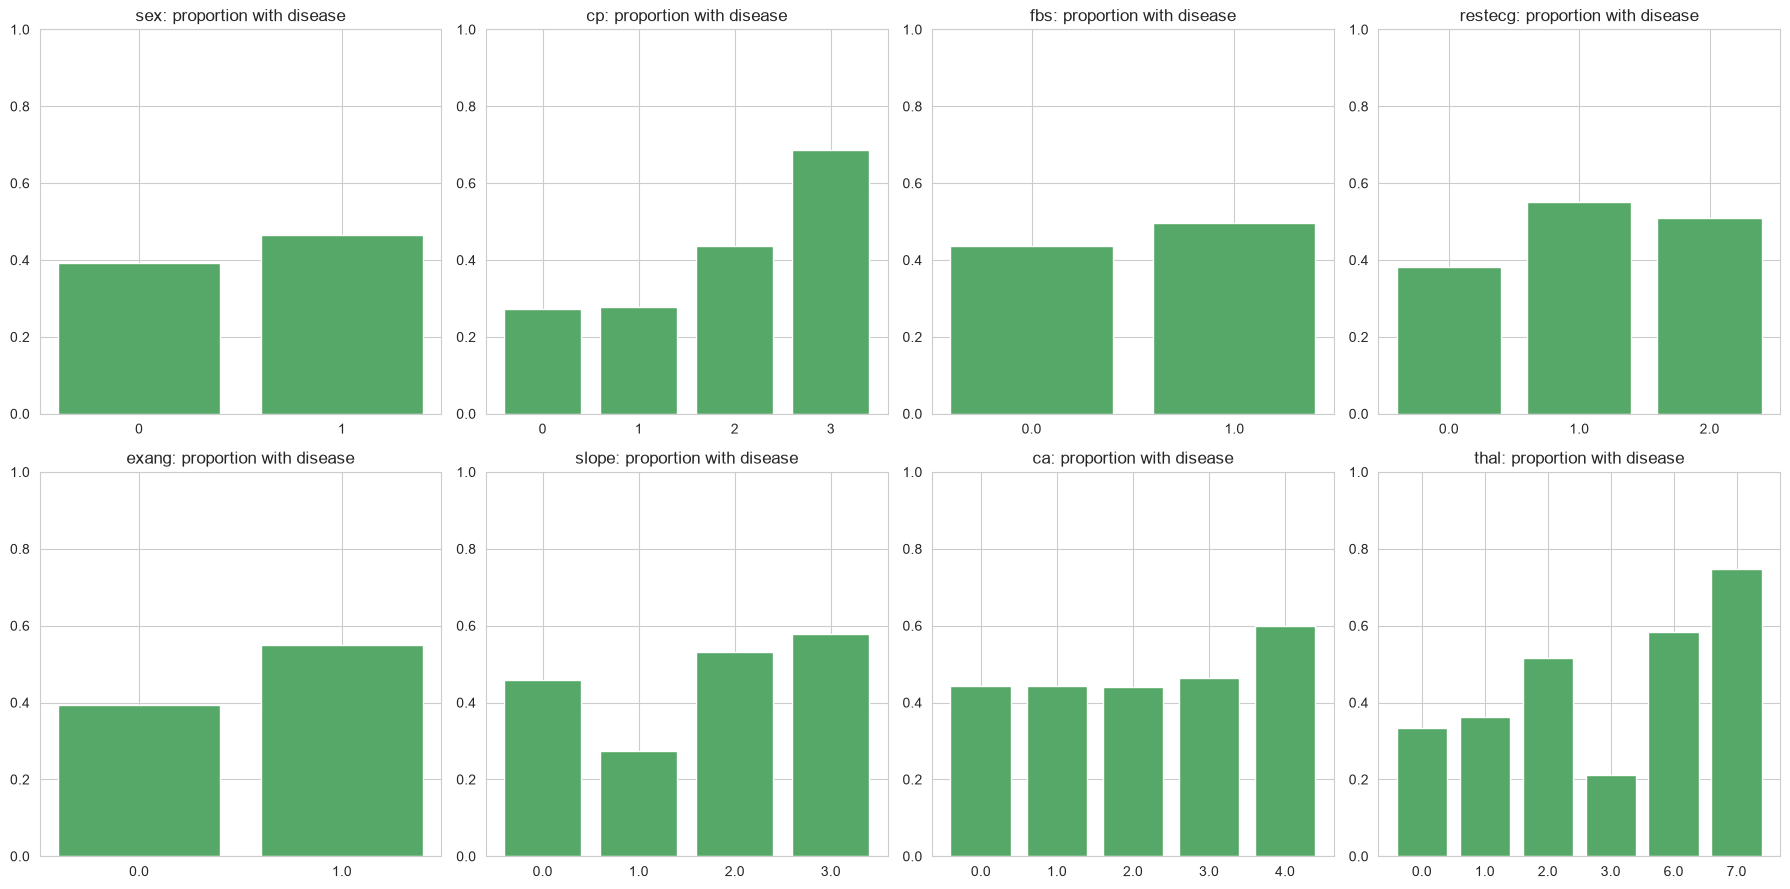

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    prop = df.groupby(col)['target'].mean()
    axes[i].bar(prop.index.astype(str), prop.values, color='#55A868')
    axes[i].set_title(f'{col}: proportion with disease')
    axes[i].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**What to look for:** `cp` (chest pain type), `exang` (exercise-induced angina), `thal`, and `ca`
show a clear split — some categories have a much higher proportion of disease than others. `fbs`
(fasting blood sugar) barely shows any difference between categories, which suggests it may not be a
very useful predictor on its own.

## 5. Correlation between features

A correlation heatmap shows which features move together, and which features correlate most with the
target itself.

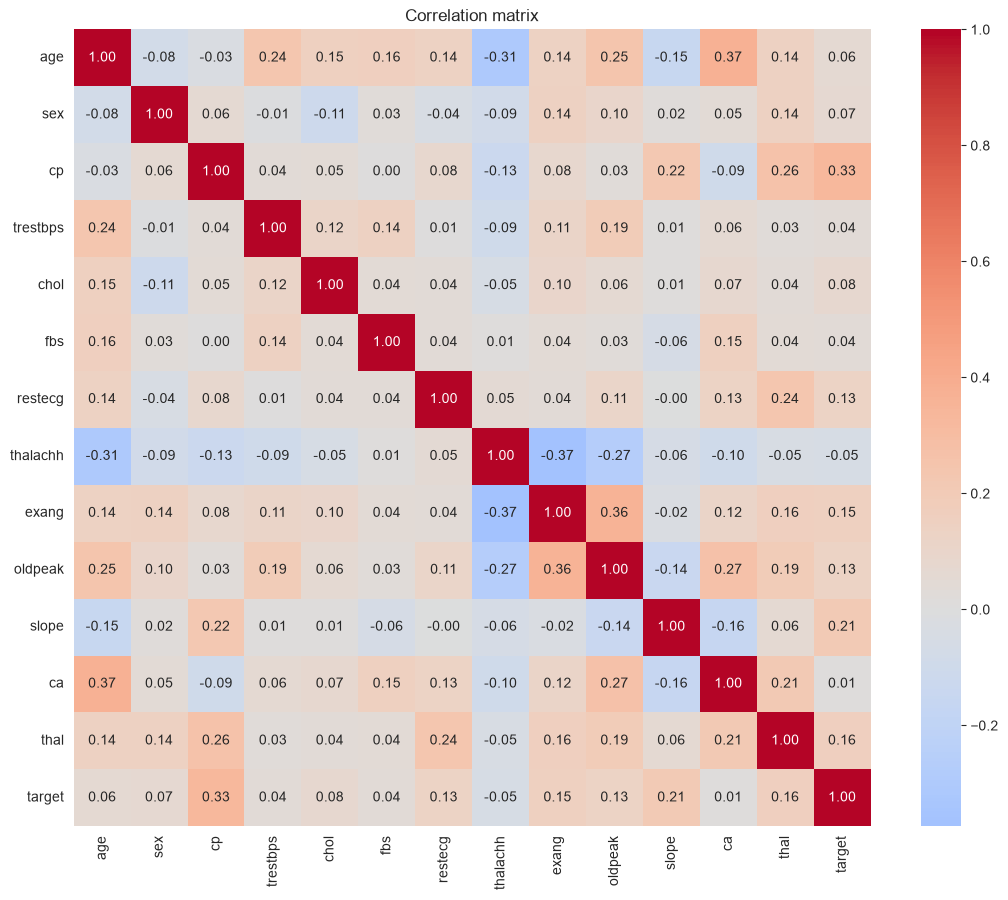

Correlation with target, sorted:
cp          0.331517
slope       0.206831
thal        0.162215
exang       0.147863
oldpeak     0.133754
restecg     0.126737
chol        0.075627
sex         0.068153
age         0.061686
thalachh   -0.048925
fbs         0.038968
trestbps    0.038680
ca          0.012465
Name: target, dtype: float64


In [6]:
plt.figure(figsize=(11, 9))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

print("Correlation with target, sorted:")
print(corr['target'].drop('target').sort_values(key=abs, ascending=False))

**What to look for:**
- No two features are so highly correlated with each other that one is redundant (nothing above ~0.8),
  so we don't need to drop any features for redundancy.
- By this measure, **`cp`, `slope`, `thal`, `exang`, and `oldpeak`** have the strongest *linear*
  relationship with the target.
- Note that `thalachh` and `ca` show a weaker linear correlation here than the earlier charts
  suggested. That's not a contradiction — correlation only captures straight-line relationships,
  while the group-wise charts in Section 4 can pick up patterns that aren't linear (e.g. risk isn't
  a straight line across `ca`'s categories). Both views are useful; we shouldn't rely on correlation
  alone to decide which features matter.

## Summary of findings

- **894 unique patients**, reasonably balanced target (~55% / 45%)
- **`cp`, `slope`, `thal`, `exang`, `oldpeak`** show the clearest *linear* relationship with the
  target (correlation); **`ca`, `thal`, `cp`, `exang`** also show clear *non-linear* group differences
  in Section 4 — between the two views, these features look like the strongest predictors overall
- **`fbs`** shows very little difference between classes in either view — may contribute little to
  the model
- No features are so strongly correlated with each other that any need to be dropped

Next step: **preprocessing** — encoding, scaling if needed, and the train/test split — before we get
into training models.